# Análisis histórico de las estrategias

Simula cada estrategia sobre el histórico diario de un activo en euros y la compara con mantener siempre (B&H). El activo se elige en la configuración (`ACTIVO`): S&P 500 (SPY con dividendos) u oro (ETF GLD), ambos convertidos a euros con EUR/USD.

Es una aproximación, no un backtest exhaustivo:

- **Retraso:** el traspaso se ejecuta `RETRASO` sesiones después de la señal (al cierre).
- **Comisión por operación** (`COMISION`). En el S&P 500, el fondo (Vanguard U.S. 500, IE0032620787) no cobra entrada ni salida según su DFI. En el oro se invertiría con un ETC, que no es traspasable: cada salida es una venta con su comisión de bróker y **tributa la ganancia**, algo que este análisis no recoge. Al final hay una tabla de sensibilidad a la comisión.
- **Liquidez:** mientras se está fuera, el dinero rinde `TIPO_LIQUIDEZ` al año (0 por defecto, lo que perjudica algo a las estrategias).
- **No incluye** impuestos ni la comisión de gestión del producto, igual en todas las estrategias.
- **Periodo:** EUR/USD en Yahoo empieza en diciembre de 2003; GLD, en noviembre de 2004.

In [1]:

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nucleo.backtest import Regla
from nucleo.datos import etiqueta, medias, posicion, precios

pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (12, 5)

## Configuración

In [2]:
ACTIVOS = {
    "sp500": ("SPY", "EURUSD=X"),  # S&P 500 con dividendos, en euros
    "oro": ("GLD", "EURUSD=X"),    # oro (ETF GLD), en euros
}
ACTIVO = "oro"
TICKER, DIVISA = ACTIVOS[ACTIVO]
ESTRATEGIAS = [
    Regla("precio/200", TICKER, ((1, 200),), DIVISA),
    Regla("6/200", TICKER, ((6, 200),), DIVISA),
    Regla("6/70", TICKER, ((6, 70),), DIVISA),
    Regla("6/70 si 70>200", TICKER, ((6, 70), (70, 200)), DIVISA),
]
RETRASO = 2          # sesiones entre la señal y la ejecución del traspaso
COMISION = 0.0       # coste por operación, en tanto por uno
TIPO_LIQUIDEZ = 0.0  # rentabilidad anual mientras se está fuera
ANIOS_DETALLE = [2008, 2011, 2013, 2015, 2018, 2020, 2022, 2025]  # años para ver las señales en el gráfico

## Datos

/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
/Users/iyantp_/anaconda3/envs/finanzas/lib/python3.12/site-packages/yfinance/utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
/Use

5521 sesiones: 2004-11-18 → 2026-10-29


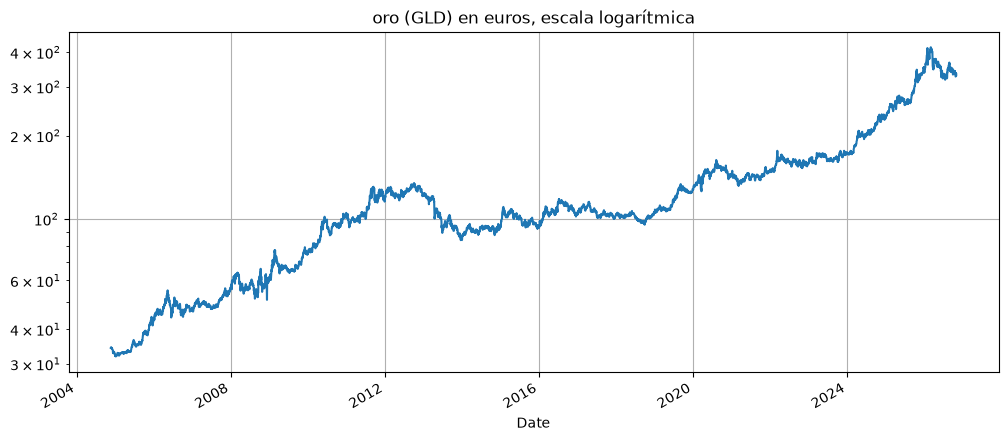

In [3]:
precio = precios(TICKER, DIVISA, periodo="max")
print(f"{len(precio)} sesiones: {precio.index[0]:%Y-%m-%d} → {precio.index[-1]:%Y-%m-%d}")
precio.plot(logy=True, title=f"{ACTIVO} ({TICKER}) en euros, escala logarítmica", grid=True);

## Simulación

`posicion` (de `nucleo/datos.py` (antes `bot/datos.py`), la misma función que usa el bot) dice para cada sesión si la regla está dentro o fuera. La rentabilidad del día *s* se cobra si la posición de `RETRASO + 1` sesiones antes era "dentro"; si no, se cobra la de la liquidez. Cada cambio de posición es un traspaso.

In [4]:
def simular(rent, dentro, comision=COMISION):
    expuesto = dentro.shift(RETRASO + 1).reindex(rent.index).astype(bool)
    traspaso = expuesto.ne(expuesto.shift())
    traspaso.iloc[0] = False
    liquidez = (1 + TIPO_LIQUIDEZ) ** (1 / 252) - 1
    return rent.where(expuesto, liquidez) - comision * traspaso, traspaso


def metricas(r, traspasos):
    valor = (1 + r).cumprod()
    anios = (r.index[-1] - r.index[0]).days / 365.25
    return {
        "rent. anual": valor.iloc[-1] ** (1 / anios) - 1,
        "volatilidad": r.std() * np.sqrt(252),
        "caída máx.": (valor / valor.cummax() - 1).min(),
        "traspasos": int(traspasos.sum()),
        "traspasos/año": traspasos.sum() / anios,
    }


posiciones = {e.nombre: posicion(precio, e.condiciones) for e in ESTRATEGIAS}
inicio = max(p.index[0] for p in posiciones.values())  # periodo común a todas
rent = precio.pct_change().loc[inicio:].iloc[RETRASO + 1:]

diarias = {"B&H": rent}
traspasos = {"B&H": pd.Series(False, index=rent.index)}
for nombre, dentro in posiciones.items():
    diarias[nombre], traspasos[nombre] = simular(rent, dentro)

print(f"Periodo evaluado: {rent.index[0]:%Y-%m-%d} → {rent.index[-1]:%Y-%m-%d}")

Periodo evaluado: 2005-09-08 → 2026-10-29


## Resumen

In [5]:
resumen = pd.DataFrame({n: metricas(diarias[n], traspasos[n]) for n in diarias}).T
resumen["% tiempo dentro"] = [1.0] + [posiciones[n].loc[rent.index[0]:].mean() for n in posiciones]
resumen.style.format({
    "rent. anual": "{:.1%}", "volatilidad": "{:.1%}", "caída máx.": "{:.1%}",
    "% tiempo dentro": "{:.0%}", "traspasos": "{:.0f}", "traspasos/año": "{:.1f}",
})

,rent. anual,volatilidad,caída máx.,traspasos,traspasos/año,% tiempo dentro
B&H,11.1%,20.2%,-37.6%,0,0.0,100%
precio/200,7.6%,17.5%,-35.8%,231,10.9,71%
6/200,8.0%,17.6%,-34.2%,81,3.8,71%
6/70,7.8%,16.7%,-29.4%,161,7.6,61%
6/70 si 70>200,7.2%,14.9%,-31.2%,101,4.8,46%


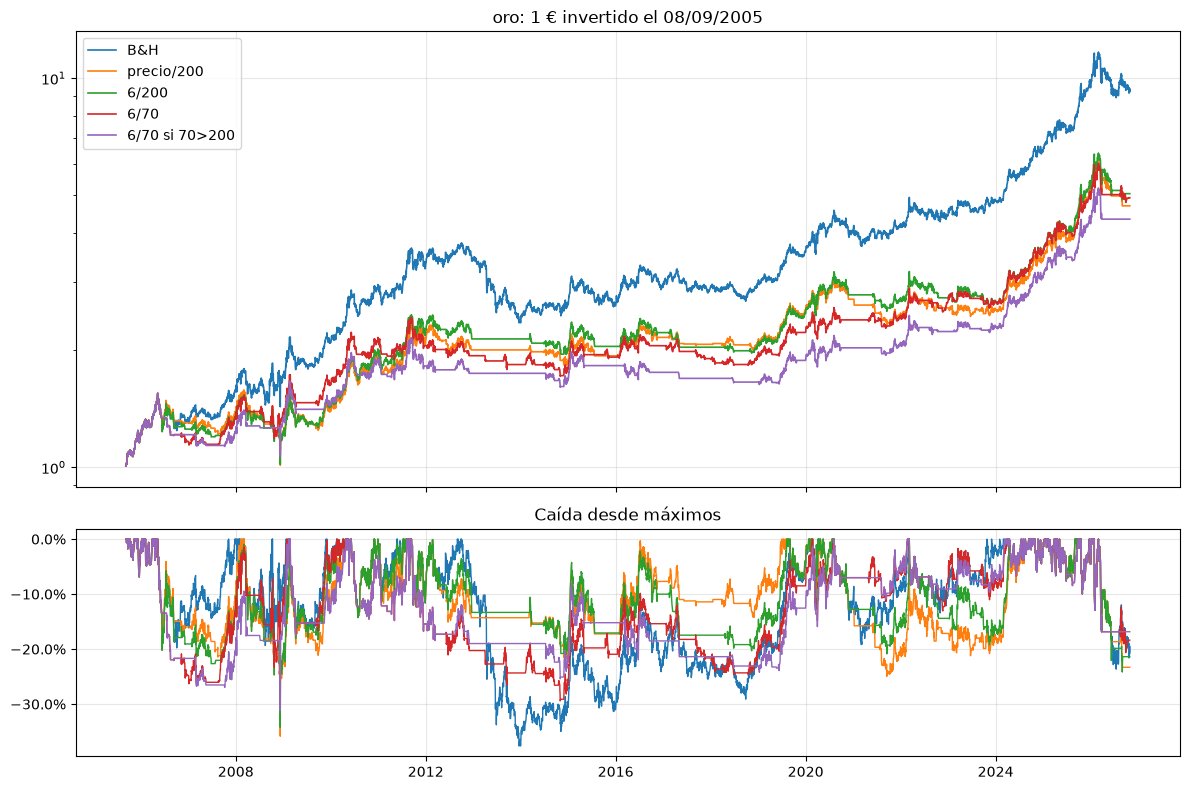

In [6]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True, height_ratios=[2, 1])
for nombre, r in diarias.items():
    valor = (1 + r).cumprod()
    ax1.plot(valor, label=nombre, lw=1.2)
    ax2.plot(valor / valor.cummax() - 1, lw=1)
ax1.set(yscale="log", title=f"{ACTIVO}: 1 € invertido el {rent.index[0]:%d/%m/%Y}")
ax2.set(title="Caída desde máximos")
ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax1.legend(); ax1.grid(alpha=0.3); ax2.grid(alpha=0.3)
fig.tight_layout()

## Por año

In [7]:
anual = pd.DataFrame({n: (1 + r).groupby(r.index.year).prod() - 1 for n, r in diarias.items()})
n_anual = pd.DataFrame({n: t.groupby(t.index.year).sum() for n, t in traspasos.items() if n != "B&H"})
tabla = pd.concat({"rentabilidad": anual, "nº traspasos": n_anual}, axis=1)
tabla.style.format("{:.1%}", subset="rentabilidad").format("{:.0f}", subset="nº traspasos") \
    .background_gradient(cmap="RdYlGn", subset="rentabilidad", vmin=-0.3, vmax=0.3)

## Señales en años concretos

Precio, medias de la estrategia y periodos fuera (sombreado). ▼ = señal de salida, ▲ = señal de entrada (el traspaso se ejecuta `RETRASO` sesiones después).

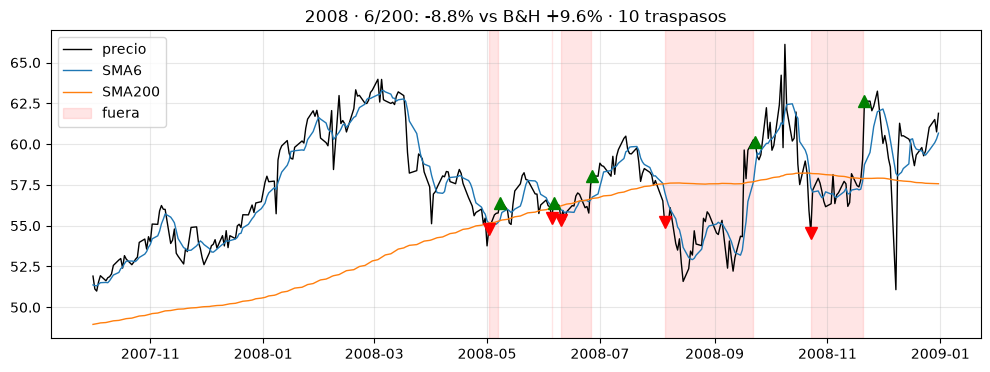

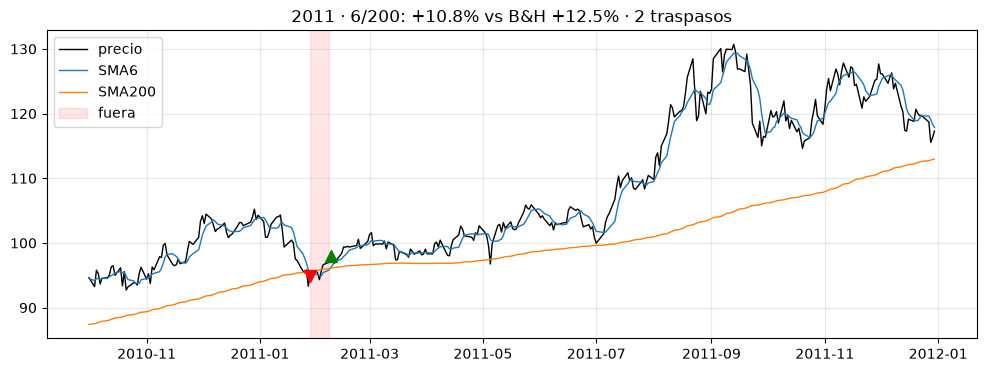

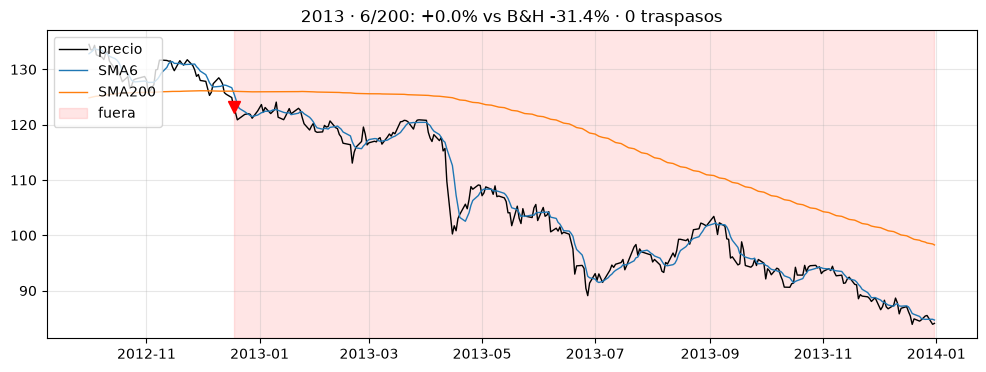

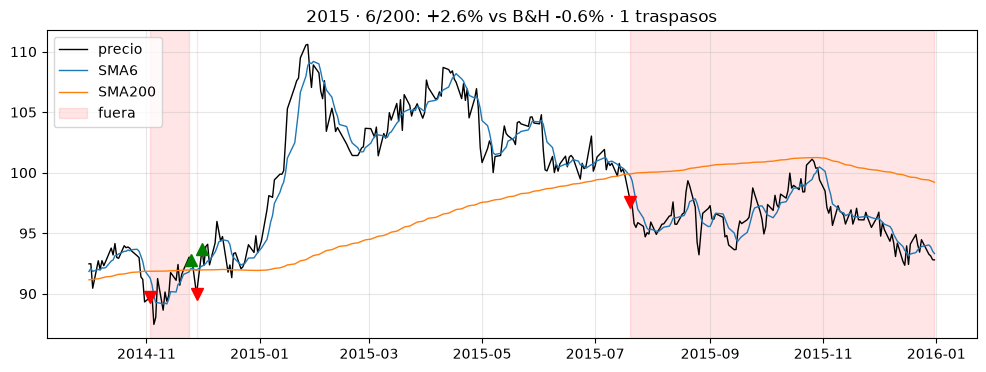

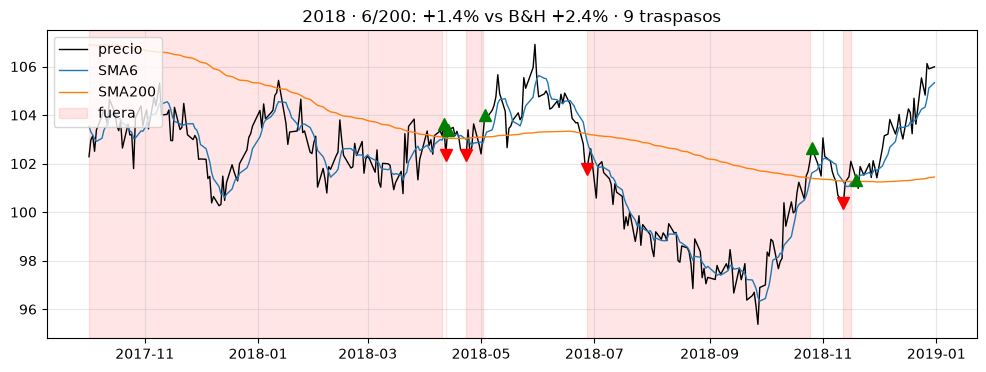

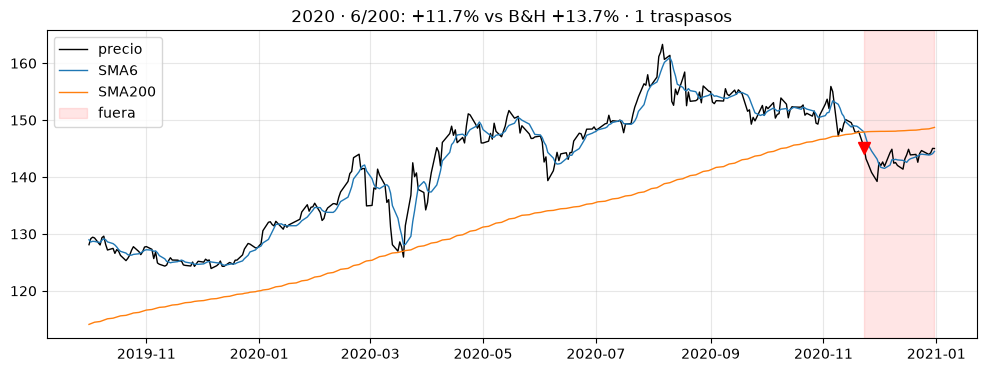

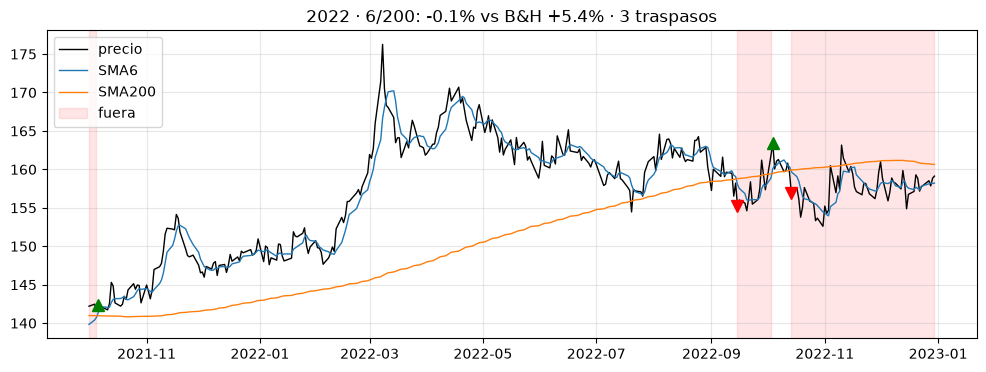

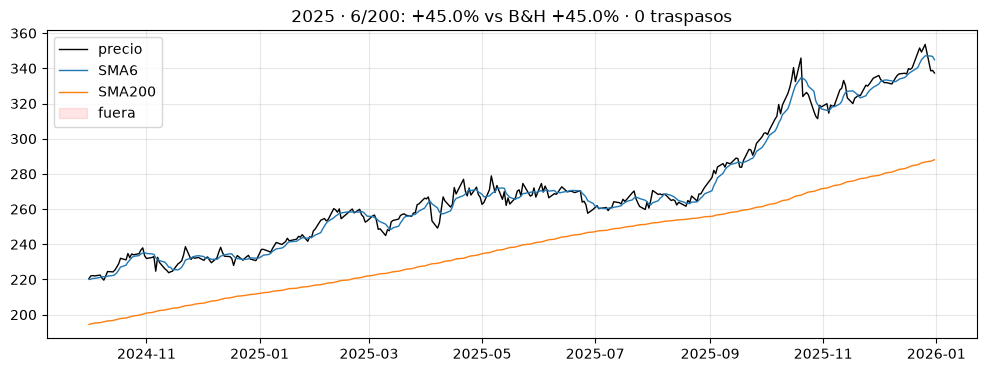

In [8]:
def ver_anio(anio, estrategia):
    regla = next(e for e in ESTRATEGIAS if e.nombre == estrategia)
    tramo = slice(f"{anio - 1}-10-01", f"{anio}-12-31")
    p = precio.loc[tramo]
    dentro = posiciones[estrategia].loc[tramo]
    sma = medias(precio, regla.condiciones).loc[tramo]
    cambios = dentro[dentro.ne(dentro.shift())].iloc[1:]

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(p, color="black", lw=1, label="precio")
    for n in sma.columns:
        if n != 1:
            ax.plot(sma[n], lw=1, label=etiqueta(n))
    ax.fill_between(dentro.index, 0, 1, where=~dentro, transform=ax.get_xaxis_transform(),
                    color="red", alpha=0.1, label="fuera")
    for fecha, entra in cambios.items():
        ax.plot(fecha, p[fecha], "^" if entra else "v", color="green" if entra else "red", ms=9)
    r = anual.loc[anio]
    ax.set_title(f"{anio} · {estrategia}: {r[estrategia]:+.1%} vs B&H {r['B&H']:+.1%} · "
                 f"{int(n_anual.loc[anio, estrategia])} traspasos")
    ax.legend(loc="upper left"); ax.grid(alpha=0.3)
    plt.show()


for anio in ANIOS_DETALLE:
    if anio in anual.index:
        ver_anio(anio, "6/200")

Para ver otra estrategia o año: `ver_anio(2022, "6/70 si 70>200")`.

## Sensibilidad a la comisión por operación

In [9]:
comisiones = [0, 0.001, 0.0025, 0.005]
sens = pd.DataFrame({
    f"{c:.2%}": {n: metricas(*simular(rent, posiciones[n], c))["rent. anual"] for n in posiciones}
    for c in comisiones
})
sens.loc["B&H"] = resumen.loc["B&H", "rent. anual"]
sens.style.format("{:.1%}")

,0.00%,0.10%,0.25%,0.50%
precio/200,7.6%,6.4%,4.7%,1.9%
6/200,8.0%,7.5%,6.9%,5.9%
6/70,7.8%,7.0%,5.8%,3.8%
6/70 si 70>200,7.2%,6.7%,5.9%,4.7%
B&H,11.1%,11.1%,11.1%,11.1%


## Lista de señales

In [10]:
estrategia = "6/200"
d = posiciones[estrategia]
cambios = d[d.ne(d.shift())].iloc[1:]
pd.DataFrame({"señal": np.where(cambios, "entrada", "salida"),
              "precio": precio[cambios.index].round(2)}, index=cambios.index.date)

/var/folders/t2/bfbzn_j5725bq_v8qcwgwzq80000gn/T/ipykernel_57917/602605645.py:4: Pandas4Warning: Inferring datetime64 from data containing datetime.date objects is deprecated. In a future version, these will be left as object dtype. Use pd.to_datetime to explicitly convert to datetime64.
  pd.DataFrame({"señal": np.where(cambios, "entrada", "salida"),


,señal,precio
2006-09-13,salida,46.17
2006-11-06,entrada,48.63
2006-12-05,salida,47.91
2007-01-23,entrada,49.32
2007-06-25,salida,47.84
...,...,...
2023-10-02,salida,160.57
2023-10-17,entrada,168.93
2026-06-10,salida,324.72
2026-08-24,entrada,365.27
